In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload both files when prompted
uploaded = files.upload()


Saving online_retail.csv to online_retail.csv
Saving trustpilot_reviews_2005.csv to trustpilot_reviews_2005.csv


In [ ]:
df_ecomm = pd.read_csv('online_retail.csv') # Changed from pd.read_excel('E_Commerce_Dataset.xlsx', sheet_name='E Comm')
df_reviews = pd.read_csv('trustpilot_reviews_2005.csv') # Changed from 'product_reviews_and_sale.csv'

print(df_ecomm.shape, df_reviews.shape)

(541909, 9) (123181, 6)


**Load Source 1: UK Online Retail transactions**

In [ ]:
df1 = pd.read_csv("online_retail.csv")  # adjust filename to what you downloaded
print(df1.shape)
print(df1.columns.tolist())
df1.head()

(541909, 9)
['index', 'InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


**Clean & check UK focus**

In [ ]:
df1 = df1.dropna(subset=['CustomerID'])
df1['InvoiceDate'] = pd.to_datetime(df1['InvoiceDate'])
df1['IsCancelled'] = df1['InvoiceNo'].astype(str).str.startswith('C')
df1 = df1[~df1['IsCancelled']]  # remove cancelled orders
df1['Revenue'] = df1['Quantity'] * df1['UnitPrice']

print(df1['Country'].value_counts().head(10))
# Confirms UK-dominance — worth reporting in your data evaluation section

Country
United Kingdom    354345
Germany             9042
France              8342
EIRE                7238
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1842
Portugal            1462
Australia           1185
Name: count, dtype: int64


**Derive the churn label**

In [ ]:
snapshot_date = df1['InvoiceDate'].max() + pd.Timedelta(days=1)

customer_summary = df1.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    FirstPurchase=('InvoiceDate', 'min')
).reset_index()

customer_summary['Tenure_days'] = (snapshot_date - customer_summary['FirstPurchase']).dt.days

# Churn rule: no purchase in the last 90 days = churned
# (justify this threshold in your report — e.g. reference to typical repurchase cycles)
customer_summary['Churn'] = (customer_summary['Recency'] > 90).astype(int)

print("Churn rate:", customer_summary['Churn'].mean().round(3))
customer_summary.head()

Churn rate: 0.334


,CustomerID,Recency,Frequency,Monetary,FirstPurchase,Tenure_days,Churn
0,12346.0,326,1,77183.60,2011-01-18 10:01:00,326,1
1,12347.0,2,7,4310.00,2010-12-07 14:57:00,367,0
2,12348.0,75,4,1797.24,2010-12-16 19:09:00,358,0
3,12349.0,19,1,1757.55,2011-11-21 09:51:00,19,0
4,12350.0,310,1,334.40,2011-02-02 16:01:00,310,1


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=customer_summary)

https://docs.google.com/spreadsheets/d/1yRc0GBW2nNlAO1RuyKD1O8j1Tuuy2crvOKXbHBglCzo/edit#gid=0


### Distribution of Star Ratings in `df_reviews`

/tmp/ipykernel_1870/927051289.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stars', data=df_reviews, palette='viridis')


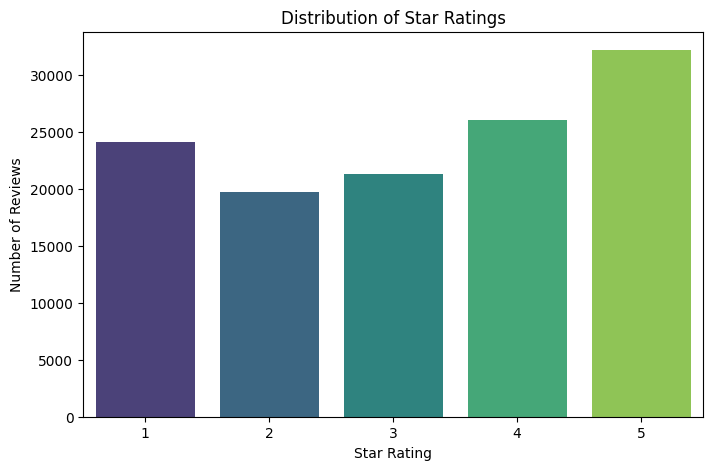

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='stars', data=df_reviews, palette='viridis')
plt.title('Distribution of Star Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Number of Reviews')
plt.show()

**Univariate analysis: Source 1**

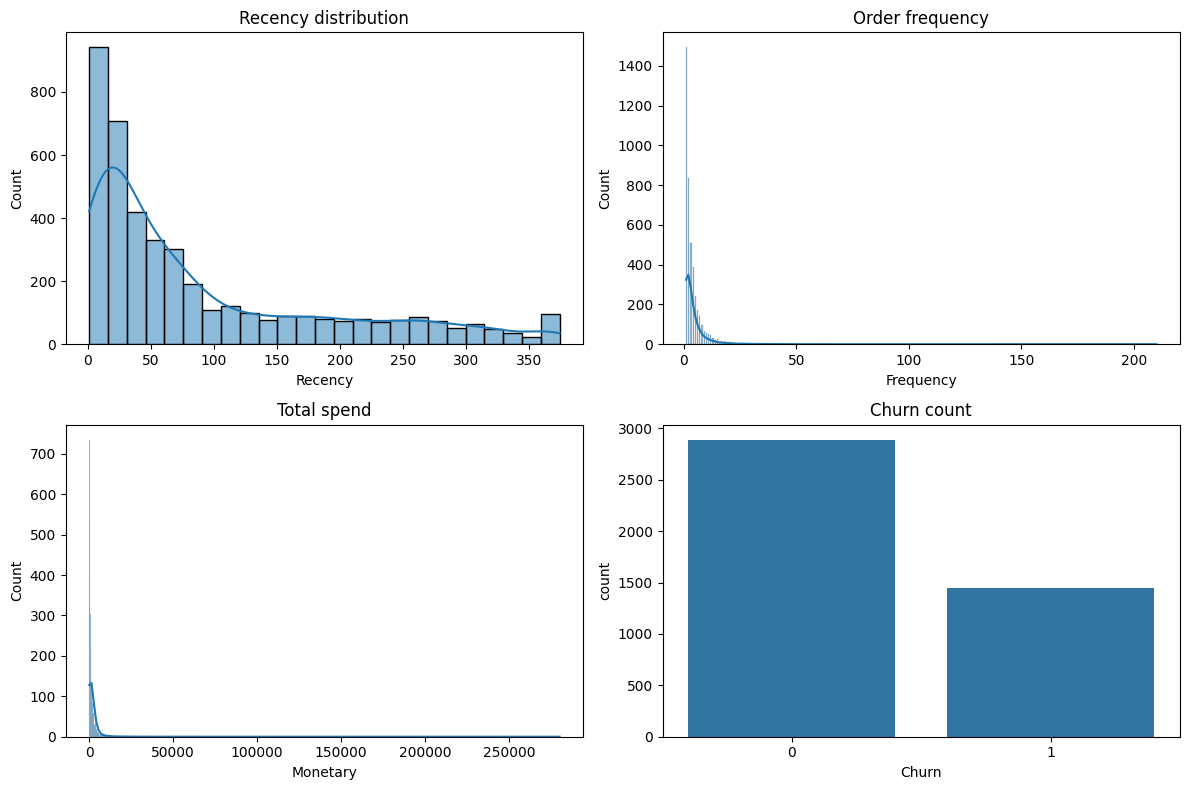

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))
sns.histplot(customer_summary['Recency'], kde=True, ax=axes[0,0]).set_title("Recency distribution")
sns.histplot(customer_summary['Frequency'], kde=True, ax=axes[0,1]).set_title("Order frequency")
sns.histplot(customer_summary['Monetary'], kde=True, ax=axes[1,0]).set_title("Total spend")
sns.countplot(x='Churn', data=customer_summary, ax=axes[1,1]).set_title("Churn count")
plt.tight_layout()
plt.show()

**Multivariate analysis: Source 1**

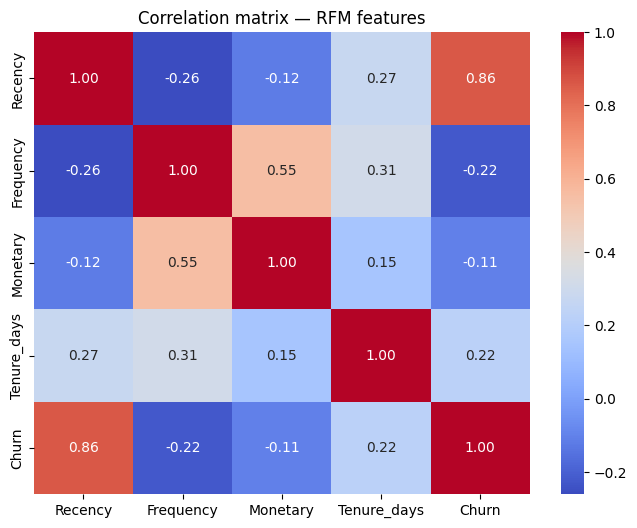

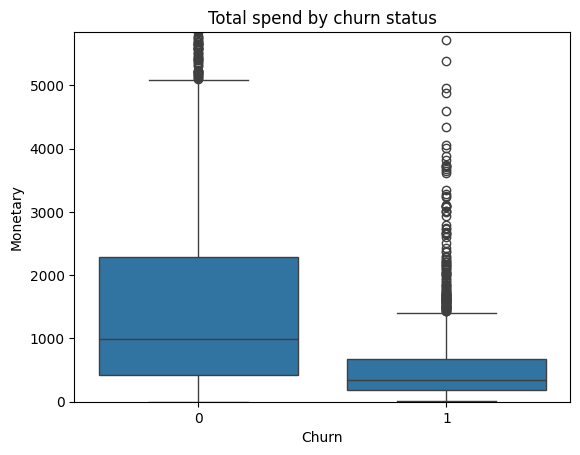

In [ ]:
num_cols = ['Recency', 'Frequency', 'Monetary', 'Tenure_days', 'Churn']
plt.figure(figsize=(8,6))
sns.heatmap(customer_summary[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix — RFM features")
plt.show()

sns.boxplot(x='Churn', y='Monetary', data=customer_summary)
plt.title("Total spend by churn status")
plt.ylim(0, customer_summary['Monetary'].quantile(0.95))  # trim outliers for readability
plt.show()

**Predictive model**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

X = customer_summary[['Recency', 'Frequency', 'Monetary', 'Tenure_days']]
y = customer_summary['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
tree = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

print("Logistic Regression AUC:", roc_auc_score(y_test, logreg.predict_proba(X_test)[:,1]).round(3))
print("Decision Tree AUC:", roc_auc_score(y_test, tree.predict_proba(X_test)[:,1]).round(3))

Logistic Regression AUC: 1.0
Decision Tree AUC: 1.0


**Load Source 2: Trustpilot UK reviews**

In [ ]:
df2 = pd.read_csv("trustpilot_reviews_2005.csv")  # adjust filename to what you downloaded
print(df2.shape)
print(df2.columns.tolist())
df2.head()

(123181, 6)
['category', 'company', 'description', 'title', 'review', 'stars']


,category,company,description,title,review,stars
0,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Great quality dog drying robe although…,Great quality dog drying robe although had to ...,5
1,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Really prompt service,"Really prompt service, The sofa covers have no...",5
2,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Life saver,I’ve purchased first of those coats in May2020...,5
3,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Brilliant coats,Brilliant coats. Really like the limited editi...,5
4,Animals & Pets,ruffandtumbledogcoats.com,At Ruff and Tumble we are proud to be the mark...,Great company and products,Great company and products. This is my 3rd dry...,5


**Check categories & filter retail**

In [ ]:
# First check what the category column is actually called and what values it has
print(df2['category'].value_counts())  # rename 'category' if the real column name differs

retail_keywords = ['retail', 'shop', 'store', 'e-commerce', 'fashion']
df2_retail = df2[df2['category'].astype(str).str.lower().str.contains('|'.join(retail_keywords), na=False)]
print(df2_retail.shape)

category
Education & Training            6365
Business Services               6190
Home & Garden                   6141
Sports                          6134
Food, Beverages & Tobacco       5895
Shopping & Fashion              5794
Vehicles & Transportation       5765
Money & Insurance               5729
Health & Medical                5646
Utilities                       5636
Electronics & Technology        5596
Animals & Pets                  5446
Travel & Vacation               5425
Home Services                   5387
Media & Publishing              5351
Construction & Manufacturing    5339
Hobbies & Crafts                5323
Events & Entertainment          5298
Restaurants & Bars              5204
Public & Local Services         5201
Beauty & Well-being             5199
Legal Services & Government     5117
Name: count, dtype: int64
(5794, 6)


**Univariate & multivariate: Source 2**

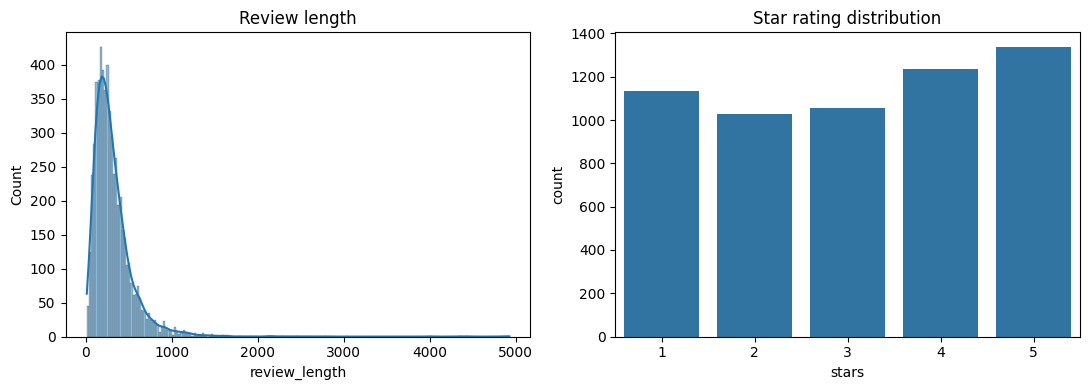

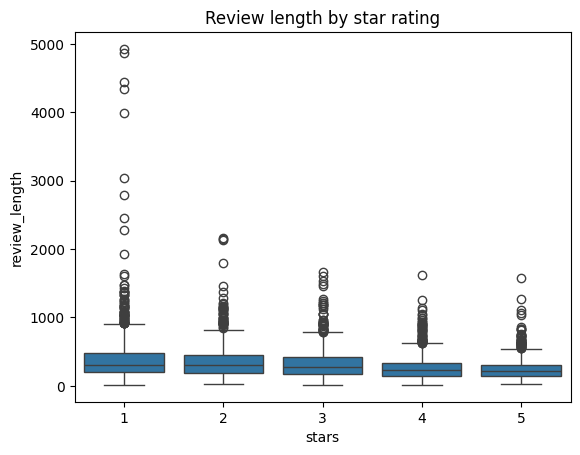

In [ ]:
text_col, rating_col = 'review', 'stars'  # Corrected column names

df2_retail.loc[:, 'review_length'] = df2_retail[text_col].astype(str).apply(len) # Used .loc to avoid SettingWithCopyWarning

fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(df2_retail['review_length'], kde=True, ax=axes[0]).set_title("Review length")
sns.countplot(x=rating_col, data=df2_retail, ax=axes[1]).set_title("Star rating distribution")
plt.tight_layout()
plt.show()

sns.boxplot(x=rating_col, y='review_length', data=df2_retail)
plt.title("Review length by star rating")
plt.show()

In [ ]:
X = customer_summary[['Frequency', 'Monetary', 'Tenure_days']]
y = customer_summary['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
tree = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

print("Logistic Regression AUC:", roc_auc_score(y_test, logreg.predict_proba(X_test)[:,1]).round(3))
print("Decision Tree AUC:", roc_auc_score(y_test, tree.predict_proba(X_test)[:,1]).round(3))

importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)

Logistic Regression AUC: 0.904
Decision Tree AUC: 0.941
Frequency      0.710426
Tenure_days    0.271619
Monetary       0.017955
dtype: float64
